In [65]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.linear_model import LinearRegression

f = pd.read_csv("./data/winemag-data-130k-v2.csv")

f.head()


,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


# Eploring the dataset

In [18]:
f.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129971 entries, 0 to 129970
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Unnamed: 0             129971 non-null  int64  
 1   country                129908 non-null  object 
 2   description            129971 non-null  object 
 3   designation            92506 non-null   object 
 4   points                 129971 non-null  int64  
 5   price                  120975 non-null  float64
 6   province               129908 non-null  object 
 7   region_1               108724 non-null  object 
 8   region_2               50511 non-null   object 
 9   taster_name            103727 non-null  object 
 10  taster_twitter_handle  98758 non-null   object 
 11  title                  129971 non-null  object 
 12  variety                129970 non-null  object 
 13  winery                 129971 non-null  object 
dtypes: float64(1), int64(2), object(11)


In [19]:
f.describe()

,Unnamed: 0,points,price
count,129971.000000,129971.000000,120975.000000
mean,64985.000000,88.447138,35.363389
std,37519.540256,3.039730,41.022218
min,0.000000,80.000000,4.000000
25%,32492.500000,86.000000,17.000000
50%,64985.000000,88.000000,25.000000
75%,97477.500000,91.000000,42.000000
max,129970.000000,100.000000,3300.000000


In [20]:
f.shape

(129971, 14)

In [21]:
f.isnull().sum()

Unnamed: 0                   0
country                     63
description                  0
designation              37465
points                       0
price                     8996
province                    63
region_1                 21247
region_2                 79460
taster_name              26244
taster_twitter_handle    31213
title                        0
variety                      1
winery                       0
dtype: int64

In [22]:
f.nunique()

Unnamed: 0               129971
country                      43
description              119955
designation               37979
points                       21
price                       390
province                    425
region_1                   1229
region_2                     17
taster_name                  19
taster_twitter_handle        15
title                    118840
variety                     707
winery                    16757
dtype: int64

In [23]:
f.country.value_counts()

country
US                        54504
France                    22093
Italy                     19540
Spain                      6645
Portugal                   5691
Chile                      4472
Argentina                  3800
Austria                    3345
Australia                  2329
Germany                    2165
New Zealand                1419
South Africa               1401
Israel                      505
Greece                      466
Canada                      257
Hungary                     146
Bulgaria                    141
Romania                     120
Uruguay                     109
Turkey                       90
Slovenia                     87
Georgia                      86
England                      74
Croatia                      73
Mexico                       70
Moldova                      59
Brazil                       52
Lebanon                      35
Morocco                      28
Peru                         16
Ukraine                      14


In [24]:
f_clean = f.dropna(subset=["price", "points"]).copy()

# Analyze data

I would like to answer primaraly on these questions

1   Does expensive wine receive higher ratings?	

2	Which countries produce the best-rated wines?	

3	Which countries offer the best value for money?	

4	Which grape varieties have the highest average ratings?	

5	Are expensive wines rated more consistently?

Does expensive wine receive higher ratings?	

In [25]:
f_clean[["price", "points"]].corr()

,price,points
price,1.000000,0.416167
points,0.416167,1.000000


Correlation of ~0.4 is a moderate pozitive one, nect step is to check this correlation based on every country that has lots of reviews

In [26]:
#f_clean.groupby("country")[["price", "points"]].corr()

big_countries = f_clean.country.value_counts()
big_countries = big_countries[big_countries > 500].index

corr_by_country = (f_clean[f_clean.country.isin(big_countries)]
                   .groupby("country")
                   .apply(lambda x: x["price"].corr(x["points"]))
                   .sort_values(ascending=False))
corr_by_country

C:\Users\flori\AppData\Local\Temp\ipykernel_24500\3040227064.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x["price"].corr(x["points"]))


country
Argentina       0.568168
South Africa    0.566197
Italy           0.528073
New Zealand     0.483961
Chile           0.480307
Spain           0.471112
Australia       0.466198
Germany         0.453121
US              0.453079
Portugal        0.440235
France          0.405829
Austria         0.392841
dtype: float64

Which countries produce best rating wines 

In [43]:
country_stats = (
    f_clean.groupby("country")
    .agg(avg_price=("price", "mean"), avg_points=("points", "mean"), nr_reviews=("country", "size"))
)

reliable = country_stats[country_stats.nr_reviews > 5].copy()

reliable.sort_values("avg_points", ascending=False)


,avg_price,avg_points,nr_reviews
country,,,
England,51.681159,91.550725,69
India,13.333333,90.222222,9
Austria,30.762772,90.190782,2799
Germany,42.257547,89.836321,2120
Canada,35.712598,89.377953,254
Hungary,40.648276,89.165517,145
France,41.139120,88.734867,17776
Luxembourg,23.333333,88.666667,6
Italy,39.663770,88.618186,16914


A note is that Austria has the smalles correlation in (price, points), but has on average one of the most points

I would to see if a country has more reviews is it more likely to have better wines

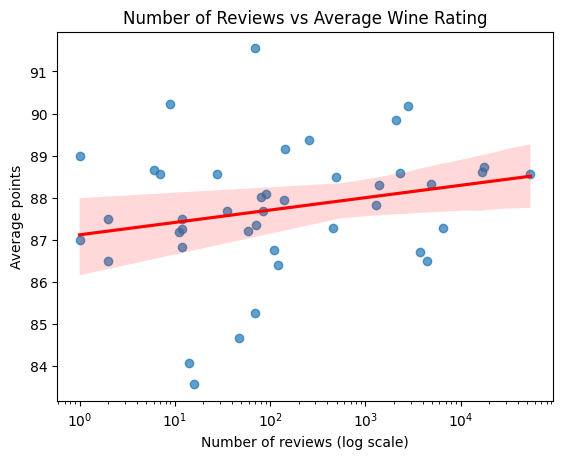

In [32]:
sns.regplot(
    data=country_stats,
    x="nr_reviews",
    y="avg_points",
    logx=True,
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"}
)

plt.xscale("log")
plt.xlabel("Number of reviews (log scale)")
plt.ylabel("Average points")
plt.title("Number of Reviews vs Average Wine Rating")
plt.show()

Which countries offer the best value for money?	

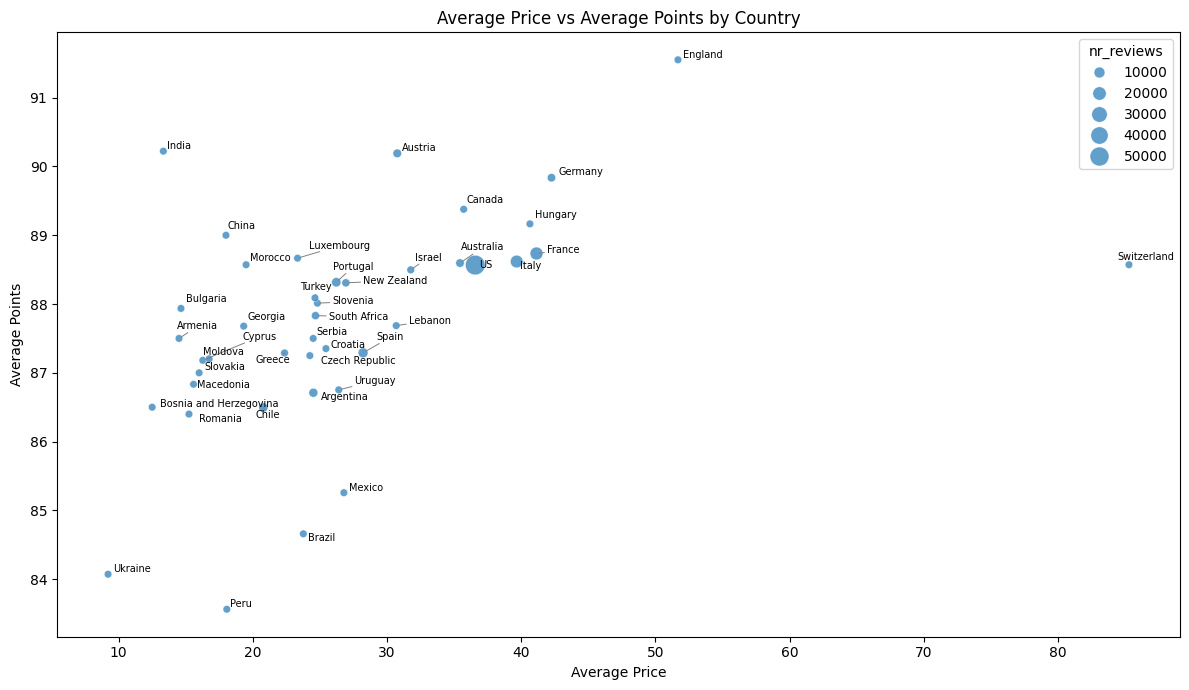

In [56]:
from adjustText import adjust_text

plt.figure(figsize=(12, 7))

ax = sns.scatterplot(
    data=country_stats,
    x = "avg_price",
    y = "avg_points",
    size = "nr_reviews",
    sizes = (30, 200),
    alpha = 0.7
)

""" for country, row in country_stats.iterrows():
    plt.annotate(
        country,
        (row["avg_price"], row["avg_points"]),
        fontsize=8,
        xytext=(10, 10),
        textcoords="offset points"
    ) """
texts = []
for country, row in country_stats.iterrows():
    texts.append(
            ax.text(
                row["avg_price"],
                row["avg_points"],
                country,
                fontsize=7
            )
        )
adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(
        arrowstyle="-",
        color="gray",
        lw=0.7
    )
)



plt.xlabel("Average Price")
plt.ylabel("Average Points")
plt.title("Average Price vs Average Points by Country")
plt.tight_layout()
plt.show()

In [57]:
f["price_category"] = pd.cut(
    f["price"],
    bins=[0, 15, 25, 40, 60, 100, 200, 500, 1000, float("inf")],
    labels=["0-15", "15-25", "25-40", "40-60", "60-100", "100-200", "200-500", "500-1000", "1000+"]
)

value_by_country = f.groupby(["country", "price_category"], observed=True).agg(avg_points=("points", "mean")).reset_index()

value_by_country.sort_values(["price_category", "avg_points"], ascending=[True, False])

value_by_country

,country,price_category,avg_points
0,Argentina,0-15,84.885698
1,Argentina,15-25,86.917820
2,Argentina,25-40,88.756818
3,Argentina,40-60,90.425339
4,Argentina,60-100,91.427632
...,...,...,...
200,Uruguay,15-25,86.661017
201,Uruguay,25-40,87.615385
202,Uruguay,40-60,89.285714
203,Uruguay,60-100,84.000000


In [62]:
wines = f.dropna(subset=["price", "points", "country"]).copy()


In [61]:
wines.info()

<class 'pandas.core.frame.DataFrame'>
Index: 120916 entries, 1 to 129970
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype   
---  ------                 --------------   -----   
 0   Unnamed: 0             120916 non-null  int64   
 1   country                120916 non-null  object  
 2   description            120916 non-null  object  
 3   designation            86148 non-null   object  
 4   points                 120916 non-null  int64   
 5   price                  120916 non-null  float64 
 6   province               120916 non-null  object  
 7   region_1               101400 non-null  object  
 8   region_2               50292 non-null   object  
 9   taster_name            96420 non-null   object  
 10  taster_twitter_handle  91500 non-null   object  
 11  title                  120916 non-null  object  
 12  variety                120915 non-null  object  
 13  winery                 120916 non-null  object  
 14  price_category         12

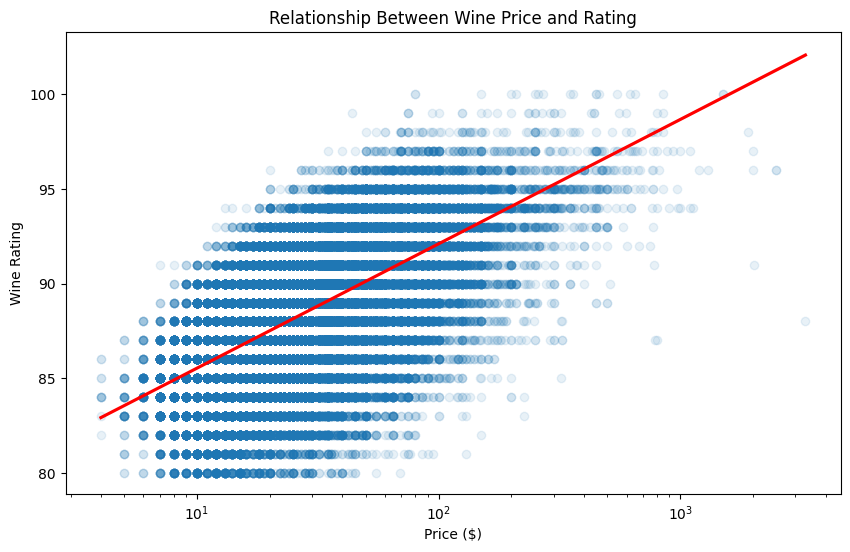

In [64]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=wines,
    x="price",
    y="points",
    logx=True,
    scatter_kws={"alpha": 0.1},
    line_kws={"color": "red"}
)

plt.xscale("log")

plt.xlabel("Price ($)")
plt.ylabel("Wine Rating")
plt.title("Relationship Between Wine Price and Rating")

plt.show()

In [ ]:
X = np.log10(wines[["price"]])
Y = wines["points"]

model = LinearRegression()
model.fit(X, Y)

wines["predicted_points"] = model.predict(X)

wines["residuals"] = wines["points"] - wines["predicted_points"]

country_value = (
    wines.groupby("country")
    .agg(avg_residual=("residuals", "mean"),
        avg_price=("price", "mean"),
        avg_points=("points", "mean"),
        nr_reviews=("country", "size")).reset_index()
)

country_value = country_value[
    country_value["nr_reviews"] >= 15
]

country_value = country_value.sort_values(
    "avg_residual",
    ascending=False
)

country_value.head(10)

KeyError: 'avg_residual'